In [5]:
import subprocess
subprocess.run(['pip', 'install', 'prophet', 'pandas', 'numpy', 'matplotlib', 'psycopg2-binary', 'flask', 'flask-cors'])

CompletedProcess(args=['pip', 'install', 'prophet', 'pandas', 'numpy', 'matplotlib', 'psycopg2-binary', 'flask', 'flask-cors'], returncode=0)

In [6]:
import pandas as pd
import psycopg2

# Lidhu me PostgreSQL
conn = psycopg2.connect(
    host="localhost",
    database="web_analytics_platform",
    user="postgres",
    password="123456",
    port=5433
)

# Merr të dhënat e transaksioneve
query = """
    SELECT 
        DATE_TRUNC('month', transaction_date) AS ds,
        SUM(amount) AS y
    FROM transactions
    WHERE business_id = 1
    GROUP BY ds
    ORDER BY ds
"""

df = pd.read_sql(query, conn)
conn.close()

print(f"✅ U lidh me PostgreSQL!")
print(f"📊 Të dhëna: {len(df)} muaj")
print(df)

✅ U lidh me PostgreSQL!
📊 Të dhëna: 5 muaj
          ds       y
0 2026-01-01  1500.0
1 2026-02-01  2300.5
2 2026-03-01   980.0
3 2026-04-01  3200.0
4 2026-06-01   370.5


C:\Users\arbab\AppData\Local\Temp\ipykernel_32736\2305123665.py:24: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


10:52:29 - cmdstanpy - INFO - Chain [1] start processing


📊 Të dhënat për Prophet:
          ds       y
0 2026-01-01  1500.0
1 2026-02-01  2300.5
2 2026-03-01   980.0
3 2026-04-01  3200.0
4 2026-06-01   370.5


10:52:29 - cmdstanpy - INFO - Chain [1] done processing



🔮 Parashikimet për 6 muajt e ardhshëm:
           ds          yhat    yhat_lower    yhat_upper
5  2026-07-01  -2233.916460  -2233.916477  -2233.916443
6  2026-08-01  38215.620236  38215.620180  38215.620294
7  2026-09-01   5669.515273   5669.515155   5669.515393
8  2026-10-01   6725.865488   6725.865299   6725.865678
9  2026-11-01 -24178.117850 -24178.118106 -24178.117581
10 2026-12-01 -28273.337650 -28273.338007 -28273.337276


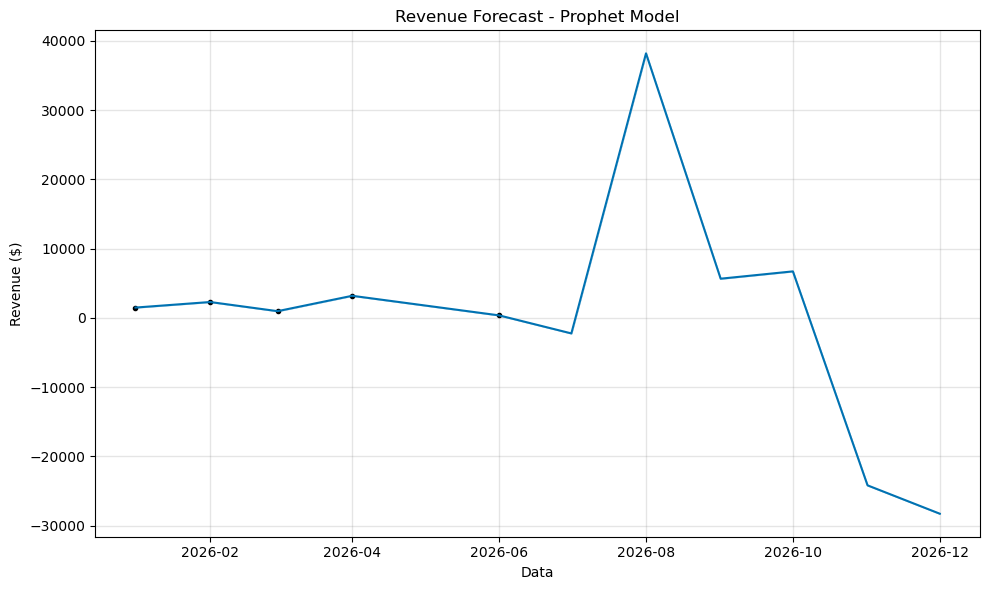

In [7]:
from prophet import Prophet
import matplotlib.pyplot as plt

# Prophet kërkon kolona 'ds' (datë) dhe 'y' (vlerë)
df['ds'] = pd.to_datetime(df['ds'])
df['y'] = df['y'].astype(float)

print("📊 Të dhënat për Prophet:")
print(df)

# Krijo dhe trajno modelin
model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    changepoint_prior_scale=0.05
)
model.fit(df)

# Parashiko 6 muajt e ardhshëm
future = model.make_future_dataframe(periods=6, freq='MS')
forecast = model.predict(future)

# Shfaq rezultatet
print("\n🔮 Parashikimet për 6 muajt e ardhshëm:")
print(forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail(6))

# Vizualizim
fig = model.plot(forecast)
plt.title('Revenue Forecast - Prophet Model')
plt.xlabel('Data')
plt.ylabel('Revenue ($)')
plt.tight_layout()
plt.show()

In [8]:
# Ruaj parashikimet në databazë
conn = psycopg2.connect(
    host="localhost",
    database="web_analytics_platform",
    user="postgres",
    password="123456",
    port=5433
)
cursor = conn.cursor()

# Merr vetëm parashikimet e ardhshme (jo historike)
future_forecast = forecast[forecast['ds'] > df['ds'].max()][['ds', 'yhat']]

# Krijo një model_run të ri
cursor.execute("""
    INSERT INTO model_runs (business_id, kpi_id, status)
    VALUES (1, 1, 'Completed')
    RETURNING run_id
""")
run_id = cursor.fetchone()[0]

# Ruaj çdo parashikim
for _, row in future_forecast.iterrows():
    cursor.execute("""
        INSERT INTO forecasts (run_id, forecast_date, forecast_value)
        VALUES (%s, %s, %s)
    """, (run_id, row['ds'].date(), round(float(row['yhat']), 2)))

conn.commit()
cursor.close()
conn.close()

print(f"✅ U ruajtën {len(future_forecast)} parashikime në databazë!")
print(future_forecast)

✅ U ruajtën 6 parashikime në databazë!
           ds          yhat
5  2026-07-01  -2233.916460
6  2026-08-01  38215.620236
7  2026-09-01   5669.515273
8  2026-10-01   6725.865488
9  2026-11-01 -24178.117850
10 2026-12-01 -28273.337650


In [9]:
import subprocess
subprocess.run(['pip', 'install', 'tensorflow', 'scikit-learn'])

CompletedProcess(args=['pip', 'install', 'tensorflow', 'scikit-learn'], returncode=0)

🤖 Parashikimet LSTM:
          ds         yhat
0 2026-07-01  1607.014404
1 2026-08-01  1681.814575
2 2026-09-01  1433.268433
3 2026-10-01  1607.195557
4 2026-11-01  1598.461914
5 2026-12-01  1583.036377


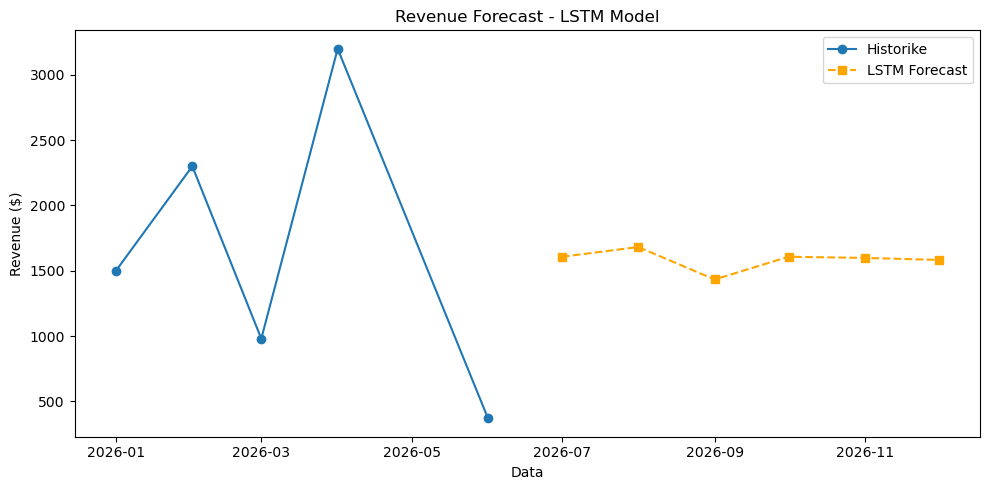

In [10]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
import warnings
warnings.filterwarnings('ignore')

# Përgatit të dhënat
scaler = MinMaxScaler()
values = df['y'].values.reshape(-1, 1)
scaled = scaler.fit_transform(values)

# Krijo sekuenca për LSTM
def create_sequences(data, seq_len=3):
    X, y = [], []
    for i in range(len(data) - seq_len):
        X.append(data[i:i+seq_len])
        y.append(data[i+seq_len])
    return np.array(X), np.array(y)

seq_len = min(3, len(scaled)-1)
X, y_train = create_sequences(scaled, seq_len)

# Ndërto modelin LSTM
model_lstm = Sequential([
    LSTM(50, activation='relu', input_shape=(seq_len, 1)),
    Dense(1)
])
model_lstm.compile(optimizer='adam', loss='mse')
model_lstm.fit(X, y_train, epochs=100, verbose=0)

# Parashiko 6 muajt e ardhshëm
predictions = []
last_seq = scaled[-seq_len:].reshape(1, seq_len, 1)

for _ in range(6):
    pred = model_lstm.predict(last_seq, verbose=0)
    predictions.append(pred[0, 0])
    last_seq = np.append(last_seq[:, 1:, :], pred.reshape(1, 1, 1), axis=1)

# Ktheje në vlera origjinale
lstm_predictions = scaler.inverse_transform(np.array(predictions).reshape(-1, 1))

# Krijo datat e ardhshme
last_date = df['ds'].max()
future_dates = pd.date_range(start=last_date + pd.DateOffset(months=1), periods=6, freq='MS')

lstm_df = pd.DataFrame({
    'ds': future_dates,
    'yhat': lstm_predictions.flatten()
})

print("🤖 Parashikimet LSTM:")
print(lstm_df)

# Vizualizim
plt.figure(figsize=(10, 5))
plt.plot(df['ds'], df['y'], label='Historike', marker='o')
plt.plot(lstm_df['ds'], lstm_df['yhat'], label='LSTM Forecast', marker='s', linestyle='--', color='orange')
plt.title('Revenue Forecast - LSTM Model')
plt.xlabel('Data')
plt.ylabel('Revenue ($)')
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
# Ruaj parashikimet LSTM në PostgreSQL
conn = psycopg2.connect(
    host="localhost",
    database="web_analytics_platform",
    user="postgres",
    password="123456",
    port=5433
)
cursor = conn.cursor()

# Krijo model_run të ri për LSTM
cursor.execute("""
    INSERT INTO model_runs (business_id, kpi_id, status)
    VALUES (1, 1, 'Completed')
    RETURNING run_id
""")
run_id = cursor.fetchone()[0]

# Ruaj parashikimet
for _, row in lstm_df.iterrows():
    cursor.execute("""
        INSERT INTO forecasts (run_id, forecast_date, forecast_value)
        VALUES (%s, %s, %s)
    """, (run_id, row['ds'].date(), round(float(row['yhat']), 2)))

conn.commit()
cursor.close()
conn.close()

print(f"✅ U ruajtën {len(lstm_df)} parashikime LSTM në databazë!")
print(lstm_df)

✅ U ruajtën 6 parashikime LSTM në databazë!
          ds         yhat
0 2026-07-01  1607.014404
1 2026-08-01  1681.814575
2 2026-09-01  1433.268433
3 2026-10-01  1607.195557
4 2026-11-01  1598.461914
5 2026-12-01  1583.036377


In [13]:
import random
from datetime import datetime, timedelta

# Gjenero dataset sintetik
random.seed(42)
np.random.seed(42)

start_date = datetime(2023, 1, 1)
records = []

for i in range(10000):
    date = start_date + timedelta(days=random.randint(0, 730))
    # Shto sezonalitet — shitjet më të larta në fund të vitit
    month_factor = 1 + 0.3 * np.sin(2 * np.pi * date.month / 12)
    amount = round(random.gauss(500, 150) * month_factor, 2)
    amount = max(10, amount)  # minimumi $10
    records.append((date.strftime('%Y-%m-%d'), amount))

df_synthetic = pd.DataFrame(records, columns=['transaction_date', 'amount'])
print(f"✅ U gjeneruan {len(df_synthetic)} regjistrime!")
print(df_synthetic.head(10))
print(f"\nStatistika:")
print(df_synthetic['amount'].describe())

✅ U gjeneruan 10000 regjistrime!
  transaction_date  amount
0       2024-10-16  509.85
1       2023-09-08  461.21
2       2023-08-17  403.12
3       2024-07-12  470.58
4       2023-03-31  608.24
5       2023-04-06  604.04
6       2023-08-12  386.48
7       2024-07-28  597.05
8       2023-07-23  383.00
9       2024-03-05  353.74

Statistika:
count    10000.000000
mean       498.981346
std        184.172892
min         10.000000
25%        366.157500
50%        477.080000
75%        618.710000
max       1324.680000
Name: amount, dtype: float64


In [14]:
# Ruaj dataset sintetik në PostgreSQL për business_id=1
conn = psycopg2.connect(
    host="localhost",
    database="web_analytics_platform",
    user="postgres",
    password="123456",
    port=5433
)
cursor = conn.cursor()

inserted = 0
for _, row in df_synthetic.iterrows():
    cursor.execute("""
        INSERT INTO transactions (business_id, user_id, amount, transaction_date)
        VALUES (1, 1, %s, %s)
    """, (row['amount'], row['transaction_date']))
    inserted += 1

conn.commit()
cursor.close()
conn.close()

print(f"✅ U ruajtën {inserted} regjistrime në PostgreSQL!")

✅ U ruajtën 10000 regjistrime në PostgreSQL!


11:02:04 - cmdstanpy - INFO - Chain [1] start processing


✅ Të dhëna: 29 muaj
           ds          y
0  2023-01-01  229016.01
1  2023-02-01  250491.19
2  2023-03-01  279830.22
3  2023-04-01  258414.89
4  2023-05-01  250981.24
5  2023-06-01  204763.94
6  2023-07-01  180633.80
7  2023-08-01  149996.04
8  2023-09-01  132160.64
9  2023-10-01  159453.78
10 2023-11-01  179446.20
11 2023-12-01  197476.18
12 2024-01-01  238837.22
13 2024-02-01  259897.05
14 2024-03-01  291898.59
15 2024-04-01  243972.24
16 2024-05-01  231658.38
17 2024-06-01  192556.46
18 2024-07-01  189503.24
19 2024-08-01  156733.82
20 2024-09-01  141460.18
21 2024-10-01  163856.05
22 2024-11-01  178816.08
23 2024-12-01  227960.02
24 2026-01-01    1500.00
25 2026-02-01    2300.50
26 2026-03-01     980.00
27 2026-04-01    3200.00
28 2026-06-01     370.50


11:02:05 - cmdstanpy - INFO - Chain [1] done processing


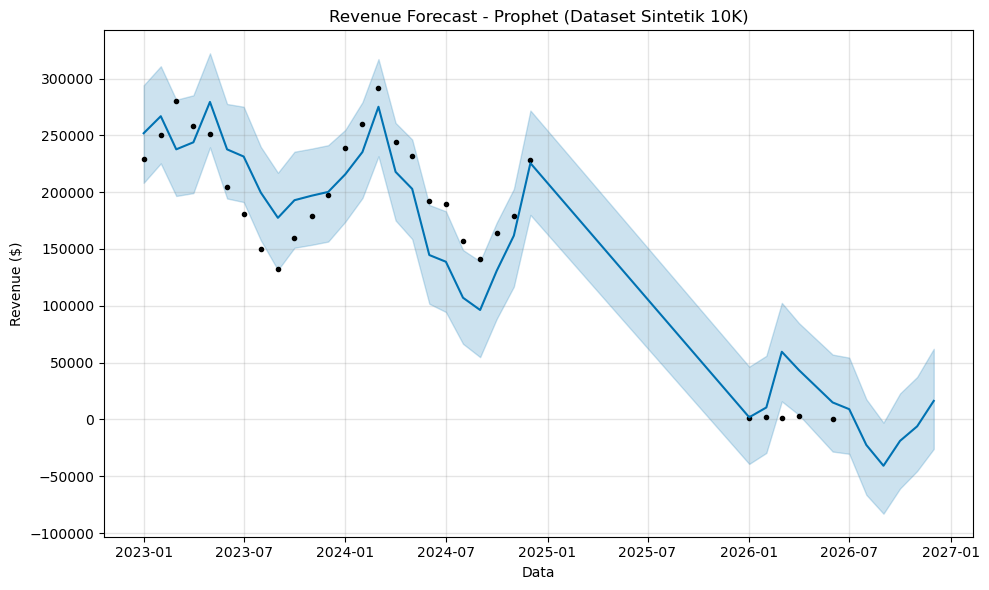


🔮 Parashikimet e reja:
           ds          yhat    yhat_lower    yhat_upper
29 2026-07-01   9070.934706 -30203.156296  54406.300680
30 2026-08-01 -22436.379922 -66323.394113  17783.106238
31 2026-09-01 -40723.504760 -82912.383848  -2787.507508
32 2026-10-01 -18837.114940 -60765.663937  22882.704373
33 2026-11-01  -6020.826042 -45330.386780  37417.666736
34 2026-12-01  16355.621154 -25926.552635  62169.482896


In [15]:
# Merr të dhënat e reja (10,000 regjistrime)
conn = psycopg2.connect(
    host="localhost",
    database="web_analytics_platform",
    user="postgres",
    password="123456",
    port=5433
)

query = """
    SELECT 
        DATE_TRUNC('month', transaction_date) AS ds,
        SUM(amount) AS y
    FROM transactions
    WHERE business_id = 1
    GROUP BY ds
    ORDER BY ds
"""

df_full = pd.read_sql(query, conn)
conn.close()

df_full['ds'] = pd.to_datetime(df_full['ds'])
df_full['y'] = df_full['y'].astype(float)

print(f"✅ Të dhëna: {len(df_full)} muaj")
print(df_full)

# Trajno Prophet me të dhëna të plota
model2 = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
)
model2.fit(df_full)

# Parashiko 6 muajt e ardhshëm
future2 = model2.make_future_dataframe(periods=6, freq='MS')
forecast2 = model2.predict(future2)

# Vizualizim
fig = model2.plot(forecast2)
plt.title('Revenue Forecast - Prophet (Dataset Sintetik 10K)')
plt.xlabel('Data')
plt.ylabel('Revenue ($)')
plt.tight_layout()
plt.show()

print("\n🔮 Parashikimet e reja:")
print(forecast2[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail(6))

📊 Metrikat e Prophet Model:
  MAE  (Mean Absolute Error):       $29,094.93
  RMSE (Root Mean Squared Error):   $33,322.01
  MAPE (Mean Absolute % Error):     412.22%


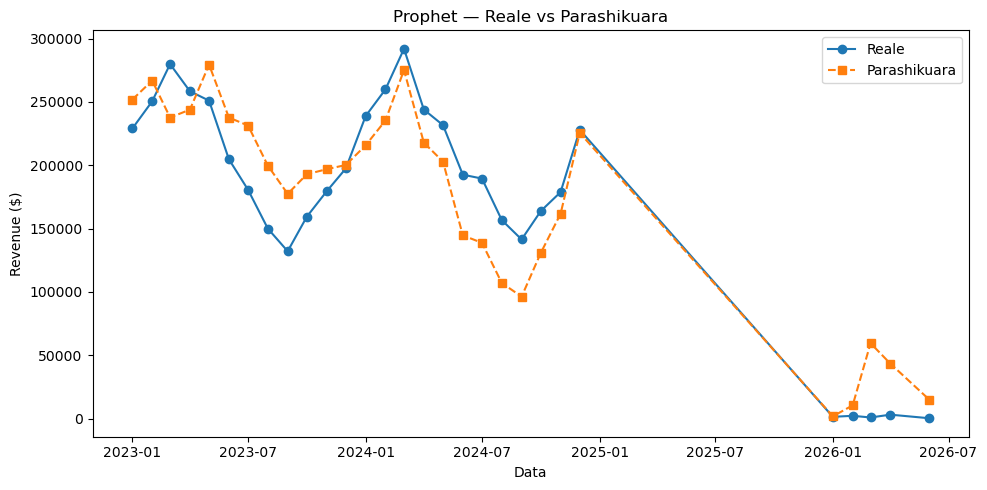

In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Krahaso parashikimet me vlerat reale (pjesa historike)
df_eval = forecast2[['ds', 'yhat']].merge(df_full, on='ds')

mae  = mean_absolute_error(df_eval['y'], df_eval['yhat'])
rmse = np.sqrt(mean_squared_error(df_eval['y'], df_eval['yhat']))
mape = np.mean(np.abs((df_eval['y'] - df_eval['yhat']) / df_eval['y'])) * 100

print("📊 Metrikat e Prophet Model:")
print(f"  MAE  (Mean Absolute Error):       ${mae:,.2f}")
print(f"  RMSE (Root Mean Squared Error):   ${rmse:,.2f}")
print(f"  MAPE (Mean Absolute % Error):     {mape:.2f}%")

# Vizualizim krahasues
plt.figure(figsize=(10, 5))
plt.plot(df_eval['ds'], df_eval['y'],    label='Reale',        marker='o')
plt.plot(df_eval['ds'], df_eval['yhat'], label='Parashikuara', marker='s', linestyle='--')
plt.title('Prophet — Reale vs Parashikuara')
plt.xlabel('Data')
plt.ylabel('Revenue ($)')
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
# LSTM me dataset të plotë
scaler2 = MinMaxScaler()
values2 = df_full['y'].values.reshape(-1, 1)
scaled2 = scaler2.fit_transform(values2)

seq_len2 = min(6, len(scaled2)-1)
X2, y2 = create_sequences(scaled2, seq_len2)

model_lstm2 = Sequential([
    LSTM(64, activation='relu', input_shape=(seq_len2, 1)),
    Dense(1)
])
model_lstm2.compile(optimizer='adam', loss='mse')
model_lstm2.fit(X2, y2, epochs=100, verbose=0)

# Parashiko
preds2 = []
last_seq2 = scaled2[-seq_len2:].reshape(1, seq_len2, 1)
for _ in range(6):
    p = model_lstm2.predict(last_seq2, verbose=0)
    preds2.append(p[0,0])
    last_seq2 = np.append(last_seq2[:, 1:, :], p.reshape(1,1,1), axis=1)

lstm_preds2 = scaler2.inverse_transform(np.array(preds2).reshape(-1,1))

# Llogarit metrikat për LSTM (në të dhënat historike)
lstm_hist = []
last_seq_h = scaled2[:seq_len2].reshape(1, seq_len2, 1)
for i in range(len(scaled2) - seq_len2):
    p = model_lstm2.predict(last_seq_h, verbose=0)
    lstm_hist.append(scaler2.inverse_transform(p)[0,0])
    last_seq_h = scaled2[i+1:i+1+seq_len2].reshape(1, seq_len2, 1)

mae_lstm  = mean_absolute_error(df_full['y'].values[seq_len2:], lstm_hist)
rmse_lstm = np.sqrt(mean_squared_error(df_full['y'].values[seq_len2:], lstm_hist))
mape_lstm = np.mean(np.abs((df_full['y'].values[seq_len2:] - np.array(lstm_hist)) / df_full['y'].values[seq_len2:])) * 100

print("📊 Metrikat e LSTM Model:")
print(f"  MAE:  ${mae_lstm:,.2f}")
print(f"  RMSE: ${rmse_lstm:,.2f}")
print(f"  MAPE: {mape_lstm:.2f}%")

# Krahasim final
print("\n📊 Krahasimi Prophet vs LSTM:")
print(f"{'Model':<10} {'MAE':>12} {'RMSE':>12} {'MAPE':>10}")
print(f"{'Prophet':<10} ${mae:>11,.2f} ${rmse:>11,.2f} {mape:>9.2f}%")
print(f"{'LSTM':<10} ${mae_lstm:>11,.2f} ${rmse_lstm:>11,.2f} {mape_lstm:>9.2f}%")

📊 Metrikat e LSTM Model:
  MAE:  $53,350.61
  RMSE: $66,465.26
  MAPE: 1461.71%

📊 Krahasimi Prophet vs LSTM:
Model               MAE         RMSE       MAPE
Prophet    $  29,094.93 $  33,322.01    412.22%
LSTM       $  53,350.61 $  66,465.26   1461.71%


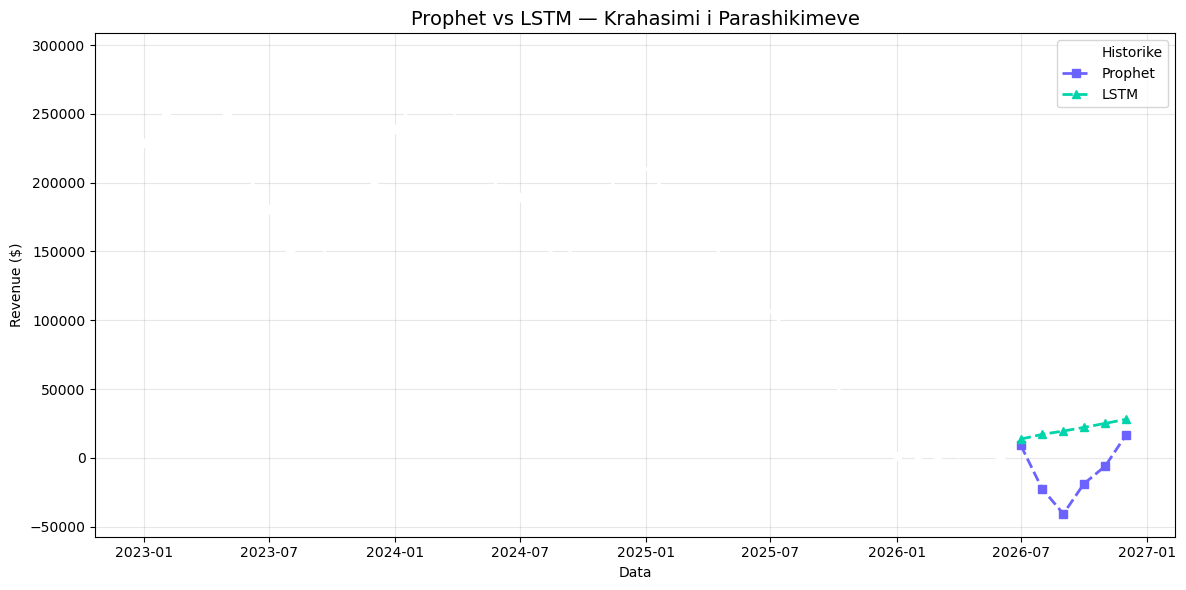

✅ Analiza e modeleve ML u përfundua!


In [18]:
# Vizualizim krahasues Prophet vs LSTM
future_dates2 = pd.date_range(
    start=df_full['ds'].max() + pd.DateOffset(months=1), 
    periods=6, freq='MS'
)

plt.figure(figsize=(12, 6))
plt.plot(df_full['ds'], df_full['y'], 
         label='Historike', marker='o', color='white', linewidth=2)
plt.plot(future_dates2, forecast2['yhat'].tail(6).values, 
         label='Prophet', marker='s', linestyle='--', color='#6c63ff', linewidth=2)
plt.plot(future_dates2, lstm_preds2.flatten(), 
         label='LSTM', marker='^', linestyle='--', color='#00d4aa', linewidth=2)

plt.title('Prophet vs LSTM — Krahasimi i Parashikimeve', fontsize=14)
plt.xlabel('Data')
plt.ylabel('Revenue ($)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("✅ Analiza e modeleve ML u përfundua!")

11:06:28 - cmdstanpy - INFO - Chain [1] start processing


Train: 20 muaj
Test:  9 muaj


11:06:31 - cmdstanpy - INFO - Chain [1] done processing



📊 Rezultatet e Testimit (Prophet):
  MAE:  $445,486.82
  RMSE: $663,698.12
  MAPE: 6027.74%


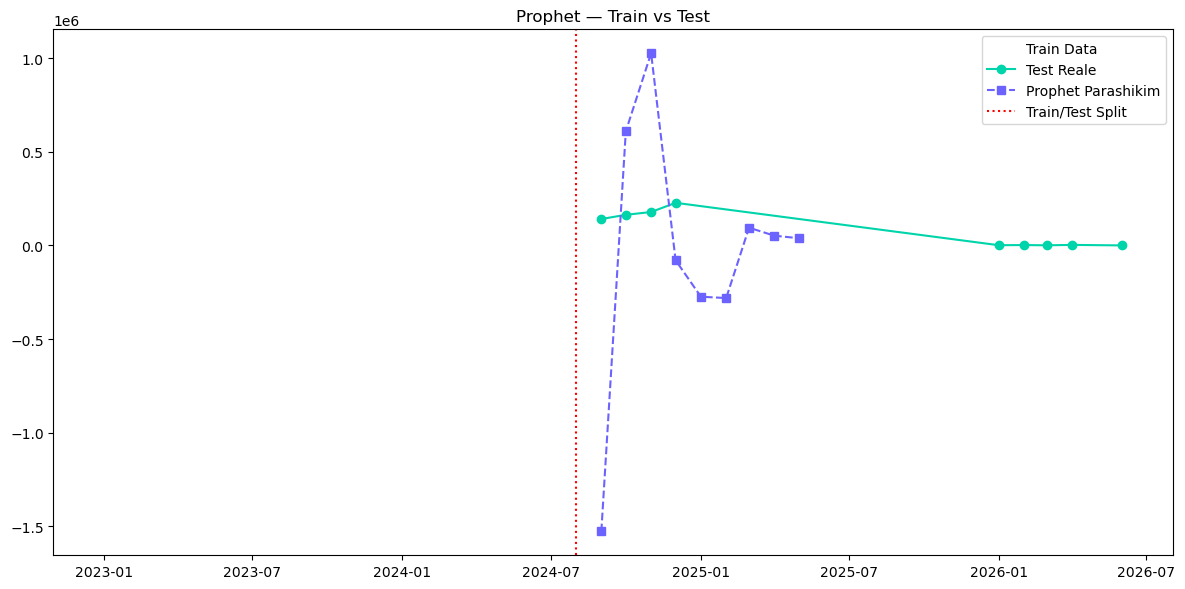

In [20]:
# Train/Test Split — 70% train, 30% test
split = int(len(df_full) * 0.7)
df_train = df_full[:split]
df_test  = df_full[split:]

print(f"Train: {len(df_train)} muaj")
print(f"Test:  {len(df_test)} muaj")

# Trajno Prophet vetëm me train data
model_test = Prophet(yearly_seasonality=True, weekly_seasonality=False)
model_test.fit(df_train)

# Parashiko për periudhën e testit
future_test = model_test.make_future_dataframe(periods=len(df_test), freq='MS')
forecast_test = model_test.predict(future_test)

# Merr vetëm parashikimet e periudhës test
pred_test = forecast_test.tail(len(df_test))[['ds','yhat']].reset_index(drop=True)
actual_test = df_test[['ds','y']].reset_index(drop=True)

# Metrikat
mae_t  = mean_absolute_error(actual_test['y'], pred_test['yhat'])
rmse_t = np.sqrt(mean_squared_error(actual_test['y'], pred_test['yhat']))
mape_t = np.mean(np.abs((actual_test['y'] - pred_test['yhat']) / actual_test['y'])) * 100

print(f"\n📊 Rezultatet e Testimit (Prophet):")
print(f"  MAE:  ${mae_t:,.2f}")
print(f"  RMSE: ${rmse_t:,.2f}")
print(f"  MAPE: {mape_t:.2f}%")

# Vizualizim
plt.figure(figsize=(12,6))
plt.plot(df_train['ds'], df_train['y'], label='Train Data', color='white')
plt.plot(actual_test['ds'], actual_test['y'], label='Test Reale', color='#00d4aa', marker='o')
plt.plot(pred_test['ds'], pred_test['yhat'], label='Prophet Parashikim', color='#6c63ff', linestyle='--', marker='s')
plt.axvline(x=df_train['ds'].max(), color='red', linestyle=':', label='Train/Test Split')
plt.title('Prophet — Train vs Test')
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
import pandas as pd

# Ngarko dataset Rossmann
df_rossmann = pd.read_csv('train.csv')

print(f"✅ Dataset u ngarkua!")
print(f"📊 Regjistrime: {len(df_rossmann):,}")
print(f"Kolonat: {list(df_rossmann.columns)}")
print(df_rossmann.head())

✅ Dataset u ngarkua!
📊 Regjistrime: 1,017,209
Kolonat: ['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']
   Store  DayOfWeek        Date  Sales  Customers  Open  Promo StateHoliday  \
0      1          5  2015-07-31   5263        555     1      1            0   
1      2          5  2015-07-31   6064        625     1      1            0   
2      3          5  2015-07-31   8314        821     1      1            0   
3      4          5  2015-07-31  13995       1498     1      1            0   
4      5          5  2015-07-31   4822        559     1      1            0   

   SchoolHoliday  
0              1  
1              1  
2              1  
3              1  
4              1  


✅ Store 1: 31 muaj të dhëna
           ds       y
0  2013-01-01  128431
1  2013-02-01  125271
2  2013-03-01  145169
3  2013-04-01  118009
4  2013-05-01  118225
5  2013-06-01  113411
6  2013-07-01  128032
7  2013-08-01  118320
8  2013-09-01  108867
9  2013-10-01  114641
10 2013-11-01  127596
11 2013-12-01  145168
12 2014-01-01  118814
13 2014-02-01  110434
14 2014-03-01  116467
15 2014-04-01  115292
16 2014-05-01  117715
17 2014-06-01  107905
18 2014-07-01  122604
19 2014-08-01  111004
20 2014-09-01  106398
21 2014-10-01  114897
22 2014-11-01  130852
23 2014-12-01  161026
24 2015-01-01  119602
25 2015-02-01  106635
26 2015-03-01  118917
27 2015-04-01  110655
28 2015-05-01  105220
29 2015-06-01  110011
30 2015-07-01  121266


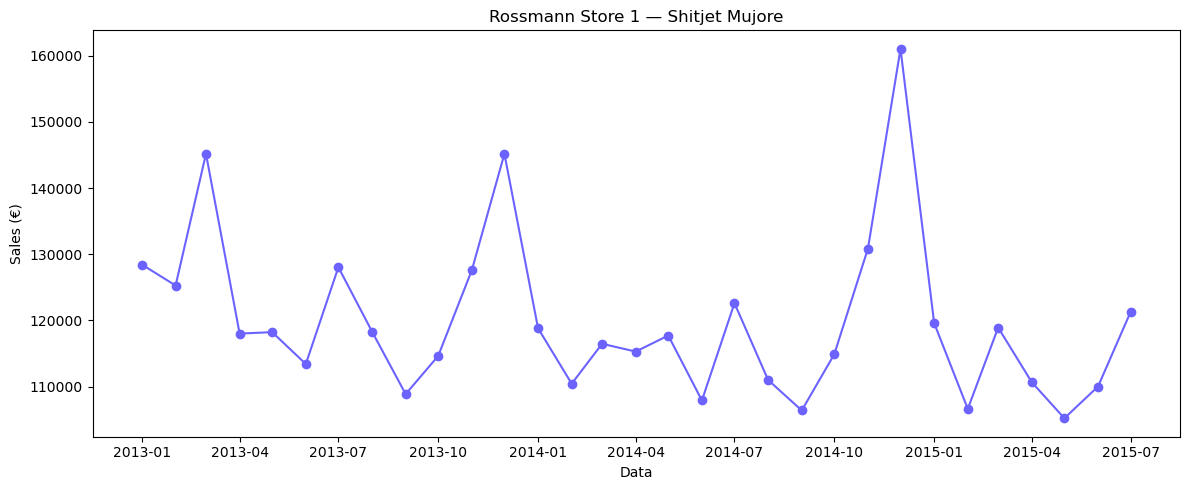

In [22]:
# Filtro vetëm Store 1 dhe ditët e hapura
df_store1 = df_rossmann[(df_rossmann['Store'] == 1) & (df_rossmann['Open'] == 1)].copy()

# Gropo sipas muajit
df_store1['Date'] = pd.to_datetime(df_store1['Date'])
df_monthly = df_store1.groupby(pd.Grouper(key='Date', freq='MS'))['Sales'].sum().reset_index()
df_monthly.columns = ['ds', 'y']
df_monthly = df_monthly[df_monthly['y'] > 0]

print(f"✅ Store 1: {len(df_monthly)} muaj të dhëna")
print(df_monthly)

# Vizualizim
plt.figure(figsize=(12,5))
plt.plot(df_monthly['ds'], df_monthly['y'], marker='o', color='#6c63ff')
plt.title('Rossmann Store 1 — Shitjet Mujore')
plt.xlabel('Data')
plt.ylabel('Sales (€)')
plt.tight_layout()
plt.show()

14:02:50 - cmdstanpy - INFO - Chain [1] start processing


Train: 24 muaj
Test:  7 muaj


14:03:00 - cmdstanpy - INFO - Chain [1] done processing



📊 Rezultatet me Rossmann (Prophet):
  MAE:  €18,464.70
  RMSE: €20,640.48
  MAPE: 16.57%


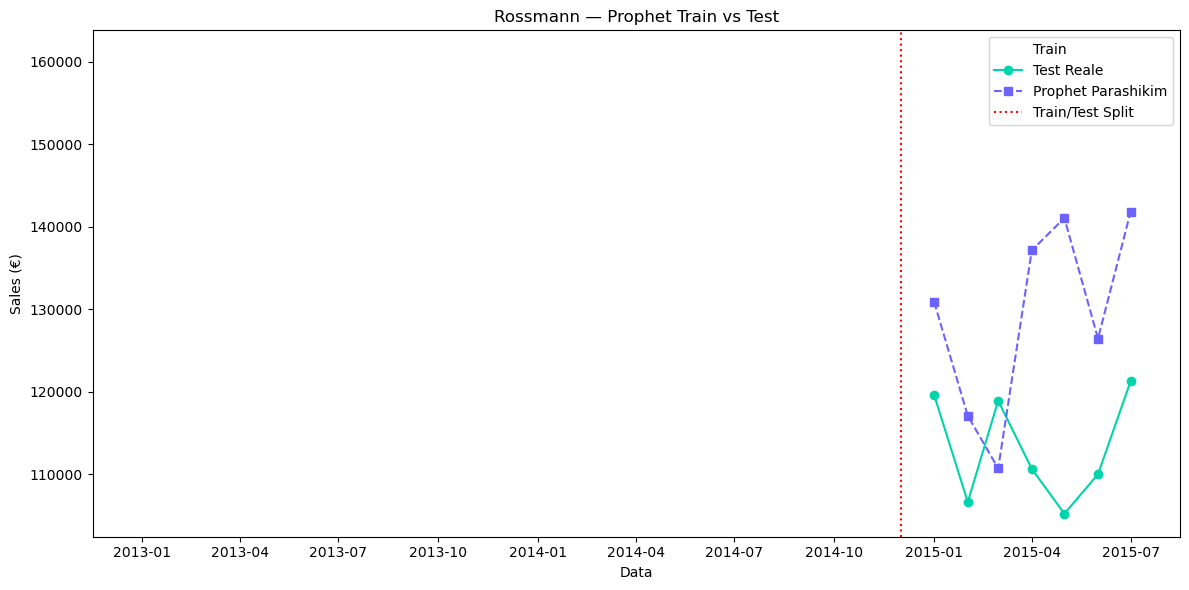

In [23]:
# Train/Test Split — 80% train, 20% test
split = int(len(df_monthly) * 0.8)
df_train_r = df_monthly[:split]
df_test_r  = df_monthly[split:]

print(f"Train: {len(df_train_r)} muaj")
print(f"Test:  {len(df_test_r)} muaj")

# Trajno Prophet me Rossmann
model_r = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    changepoint_prior_scale=0.05
)
model_r.fit(df_train_r)

# Parashiko
future_r = model_r.make_future_dataframe(periods=len(df_test_r), freq='MS')
forecast_r = model_r.predict(future_r)

# Metrikat
pred_r = forecast_r.tail(len(df_test_r))[['ds','yhat']].reset_index(drop=True)
actual_r = df_test_r[['ds','y']].reset_index(drop=True)

mae_r  = mean_absolute_error(actual_r['y'], pred_r['yhat'])
rmse_r = np.sqrt(mean_squared_error(actual_r['y'], pred_r['yhat']))
mape_r = np.mean(np.abs((actual_r['y'] - pred_r['yhat']) / actual_r['y'])) * 100

print(f"\n📊 Rezultatet me Rossmann (Prophet):")
print(f"  MAE:  €{mae_r:,.2f}")
print(f"  RMSE: €{rmse_r:,.2f}")
print(f"  MAPE: {mape_r:.2f}%")

# Vizualizim
plt.figure(figsize=(12,6))
plt.plot(df_train_r['ds'], df_train_r['y'], label='Train', color='white', marker='o')
plt.plot(actual_r['ds'], actual_r['y'], label='Test Reale', color='#00d4aa', marker='o')
plt.plot(pred_r['ds'], pred_r['yhat'], label='Prophet Parashikim', color='#6c63ff', linestyle='--', marker='s')
plt.axvline(x=df_train_r['ds'].max(), color='red', linestyle=':', label='Train/Test Split')
plt.title('Rossmann — Prophet Train vs Test')
plt.xlabel('Data')
plt.ylabel('Sales (€)')
plt.legend()
plt.tight_layout()
plt.show()

In [24]:
# LSTM me Rossmann
scaler_r = MinMaxScaler()
values_r = df_monthly['y'].values.reshape(-1,1)
scaled_r = scaler_r.fit_transform(values_r)

seq_len_r = 6
X_r, y_r = create_sequences(scaled_r, seq_len_r)

model_lstm_r = Sequential([
    LSTM(64, activation='relu', input_shape=(seq_len_r, 1)),
    Dense(1)
])
model_lstm_r.compile(optimizer='adam', loss='mse')
model_lstm_r.fit(X_r, y_r, epochs=150, verbose=0)

# Testo në test set
lstm_hist_r = []
for i in range(len(df_test_r)):
    idx = len(df_train_r) - seq_len_r + i
    seq = scaled_r[idx:idx+seq_len_r].reshape(1, seq_len_r, 1)
    p = model_lstm_r.predict(seq, verbose=0)
    lstm_hist_r.append(scaler_r.inverse_transform(p)[0,0])

mae_lr  = mean_absolute_error(actual_r['y'], lstm_hist_r)
rmse_lr = np.sqrt(mean_squared_error(actual_r['y'], lstm_hist_r))
mape_lr = np.mean(np.abs((actual_r['y'] - np.array(lstm_hist_r)) / actual_r['y'])) * 100

print(f"📊 Rezultatet me Rossmann (LSTM):")
print(f"  MAE:  €{mae_lr:,.2f}")
print(f"  RMSE: €{rmse_lr:,.2f}")
print(f"  MAPE: {mape_lr:.2f}%")

# Krahasim final
print(f"\n📊 Krahasimi Final — Rossmann:")
print(f"{'Model':<10} {'MAE':>12} {'RMSE':>12} {'MAPE':>10}")
print(f"{'Prophet':<10} €{mae_r:>11,.2f} €{rmse_r:>11,.2f} {mape_r:>9.2f}%")
print(f"{'LSTM':<10} €{mae_lr:>11,.2f} €{rmse_lr:>11,.2f} {mape_lr:>9.2f}%")

📊 Rezultatet me Rossmann (LSTM):
  MAE:  €4,943.32
  RMSE: €5,756.14
  MAPE: 4.38%

📊 Krahasimi Final — Rossmann:
Model               MAE         RMSE       MAPE
Prophet    €  18,464.70 €  20,640.48     16.57%
LSTM       €   4,943.32 €   5,756.14      4.38%
